# 1. Imports and load

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from scipy.cluster.hierarchy import linkage, dendrogram

RANDOM_STATE = 42
sns.set_palette('colorblind')

df = pd.read_csv('../data/players_fc24_clean.csv')
print(df.shape, 'missing:', df.isnull().sum().sum(), 'duplicates:', df.duplicated().sum())
df.head()

(18250, 56) missing: 0 duplicates: 0


,short_name,player_positions,overall,potential,value_eur,wage_eur,age,height_cm,weight_kg,preferred_foot,...,defending_marking_awareness,defending_standing_tackle,defending_sliding_tackle,goalkeeping_diving,goalkeeping_handling,goalkeeping_kicking,goalkeeping_positioning,goalkeeping_reflexes,goalkeeping_speed,position_group
0,K. Mbappé,"ST, LW",91,94,181500000.0,230000.0,24,182,75,Right,...,26,34,32,13,5,7,11,6,0.0,Forward
1,E. Haaland,ST,91,94,185000000.0,340000.0,22,195,94,Left,...,38,47,29,7,14,13,11,7,0.0,Forward
2,K. De Bruyne,"CM, CAM",91,91,103000000.0,350000.0,32,181,75,Right,...,66,70,53,15,13,5,10,13,0.0,Midfielder
3,L. Messi,"CF, CAM",90,90,41000000.0,23000.0,36,169,67,Left,...,20,35,24,6,11,15,14,8,0.0,Forward
4,K. Benzema,"CF, ST",90,90,51000000.0,95000.0,35,185,81,Right,...,43,24,18,13,11,5,5,7,0.0,Forward


The cleaned FC 24 player dataset (`players_fc24_clean.csv`) is loaded here. It contains 18,250 players and 56 columns, with 0 missing values and 0 duplicate rows, so no further cleaning is needed in this notebook. Clustering is unsupervised, so the true position labels are not used when fitting the models. They are only used afterwards to interpret the clusters. `RANDOM_STATE = 42` is set once and reused so the results are reproducible.

# 2. Features and scaling

In [2]:
y_true = df['position_group']                    # only used AFTER clustering
X = df.select_dtypes(include=np.number).drop(columns=['value_eur', 'wage_eur'])
print('Features used:', X.shape[1])

X_scaled = StandardScaler().fit_transform(X)     # no train/test split in clustering

rng = np.random.RandomState(RANDOM_STATE)
idx = rng.choice(len(X_scaled), size=5000, replace=False)
Xs = X_scaled[idx]                               # same 5,000-row sample for every algorithm
ys = y_true.iloc[idx].values

Features used: 49


The position label `position_group` is stored in `y_true` but is **not** used to fit any model. It is only used after clustering to interpret the clusters. The features are all numeric columns except `value_eur` and `wage_eur`, which are dropped because they are market and contract outcomes rather than player attributes. This leaves 49 features. They are standardised with `StandardScaler` so that no single feature dominates the distance calculations. No train/test split is used because clustering has no prediction step to test on held-out data. To keep the distance-based algorithms and t-SNE fast, a random sample of 5,000 players (fixed with `RANDOM_STATE`) is used, and the same sample is used for every algorithm so the results are comparable.

# 3. K-Means: elbow and silhouette

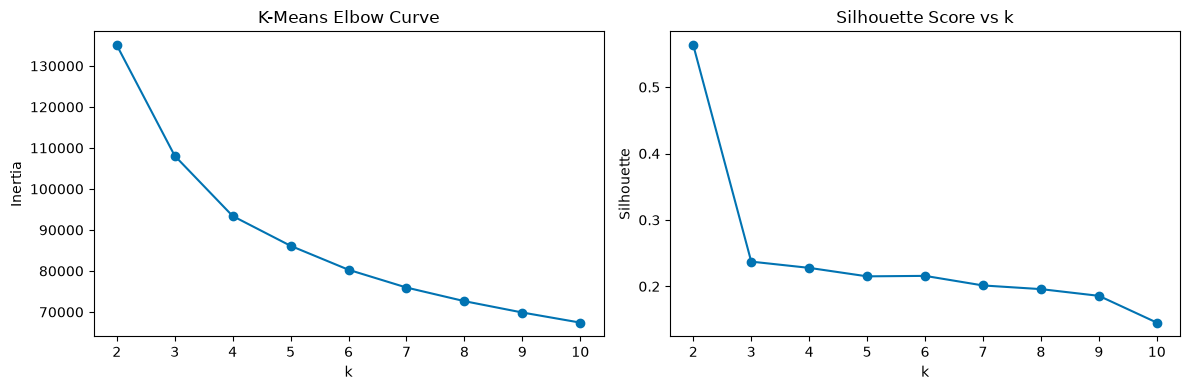

In [3]:
ks = range(2, 11)
inertias, sils = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(Xs)
    inertias.append(km.inertia_)
    sils.append(silhouette_score(Xs, km.labels_))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(list(ks), inertias, marker='o'); ax[0].set(title='K-Means Elbow Curve', xlabel='k', ylabel='Inertia')
ax[1].plot(list(ks), sils, marker='o'); ax[1].set(title='Silhouette Score vs k', xlabel='k', ylabel='Silhouette')
plt.tight_layout()
plt.savefig('../models/kmeans_elbow.png', bbox_inches='tight')
plt.show()

K-Means is run for k = 2 to 10 on the 5,000-player sample, and two measures are compared. The elbow curve shows that inertia falls steeply from k = 2 to k = 4 and then flattens, so adding more clusters beyond k = 4 gives only small gains. The silhouette score is highest at k = 2 (about 0.56), drops sharply at k = 3 (about 0.24), and then declines slowly to about 0.14 at k = 10. It is almost flat between k = 3 and k = 6, so it does not clearly favour any k in that range. I chose **k = 4** because it is where the elbow bends, and its silhouette (about 0.23) is about as good as any k from 3 to 6. I did not choose k = 2, even though it has the highest silhouette, because such a coarse split is unlikely to be useful, and the very high score suggests one group is far from the rest (probably goalkeepers versus outfield players, which I will check against the position labels later).

# 4. Fit final K-Means

In [5]:
K = 4   # choose from the elbow/silhouette plots above, and justify it in markdown
km = KMeans(n_clusters=K, n_init=10, random_state=RANDOM_STATE).fit(Xs)
km_labels = km.labels_

The final K-Means model is fitted with k = 4 on the same 5,000-player sample, using `n_init=10` and `RANDOM_STATE = 42` so the result is reproducible. The cluster labels are stored in `km_labels` and used for the metrics, plots and cross-tab below.

# 5. Dendrogram and linkage comparison

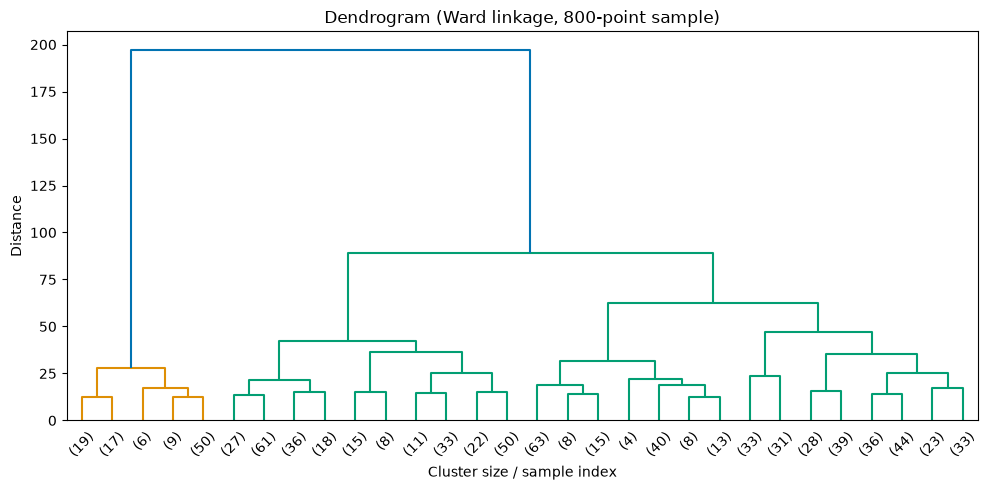

ward        0.1805
complete    0.1843
average     0.2882
Name: Silhouette, dtype: float64

In [6]:
Z = linkage(Xs[:800], method='ward')
plt.figure(figsize=(10, 5))
dendrogram(Z, truncate_mode='lastp', p=30)
plt.title('Dendrogram (Ward linkage, 800-point sample)')
plt.xlabel('Cluster size / sample index')
plt.ylabel('Distance')
plt.tight_layout()
plt.savefig('../models/dendrogram.png', bbox_inches='tight')
plt.show()

link_scores = {}
for link in ['ward', 'complete', 'average']:
    lab = AgglomerativeClustering(n_clusters=K, linkage=link).fit_predict(Xs)
    link_scores[link] = silhouette_score(Xs, lab)
pd.Series(link_scores, name='Silhouette').round(4)

In [12]:
for link in ['ward', 'complete', 'average']:
    lab = AgglomerativeClustering(n_clusters=K, linkage=link).fit_predict(Xs)
    print(link, np.bincount(lab))

ward [1398 1073 1971  558]
complete [ 558 2046   95 2301]
average [4436  558    5    1]


Three linkage methods were compared with the silhouette score on the 5,000-player sample with k = 4: Ward = 0.1805, complete = 0.1843 and average = 0.2882. Average linkage scores highest, but only because it produces a degenerate split: 4,436 players (about 89%) fall into one cluster and the other three hold just 558, 5 and 1 players, so the higher score does not mean better clusters. Ward gives much more balanced clusters (1,398, 1,073, 1,971 and 558 players), and complete linkage gives 558, 2,046, 95 and 2,301. Ward and complete have almost the same silhouette, so I use Ward linkage for the final model because its clusters are balanced and it minimises within-cluster variance, the same objective K-Means uses, which makes the two algorithms easier to compare.

# 6. Fit Agglomerative

In [7]:
agg_labels = AgglomerativeClustering(n_clusters=K, linkage='ward').fit_predict(Xs)

Agglomerative clustering is fitted with Ward linkage and the same number of clusters as K-Means (k = 4), on the same 5,000-player sample, so the two algorithms can be compared directly. The cluster labels are stored in `agg_labels` and used for the metrics, plots and cross-tab below.

# 7. Metrics table

In [8]:
def cluster_metrics(X, labels):
    return {'Silhouette': silhouette_score(X, labels),
            'Davies-Bouldin': davies_bouldin_score(X, labels),
            'Calinski-Harabasz': calinski_harabasz_score(X, labels)}

metrics_df = pd.DataFrame({'K-Means': cluster_metrics(Xs, km_labels),
                           'Agglomerative': cluster_metrics(Xs, agg_labels)}).T
metrics_df.round(4)

,Silhouette,Davies-Bouldin,Calinski-Harabasz
K-Means,0.2278,1.4381,2703.4459
Agglomerative,0.1805,1.7156,2281.6068


Both algorithms are scored on the same 5,000-player sample with three internal metrics. Higher is better for Silhouette and Calinski-Harabasz, and lower is better for Davies-Bouldin.

| Algorithm | Silhouette | Davies-Bouldin | Calinski-Harabasz |
|---|---|---|---|
| K-Means | 0.2278 | 1.4381 | 2,703.45 |
| Agglomerative (Ward) | 0.1805 | 1.7156 | 2,281.61 |

K-Means is better on all three metrics, so it gives the more compact and better-separated clusters on this data. The absolute silhouette values are low (well below 0.5), which means the clusters overlap and are not sharply separated. This is realistic for football roles, because many positions share similar attributes. These scores are computed on a 5,000-player sample, so they would change slightly with a different sample.

# 8. PCA plots

Variance explained: [0.539 0.121]


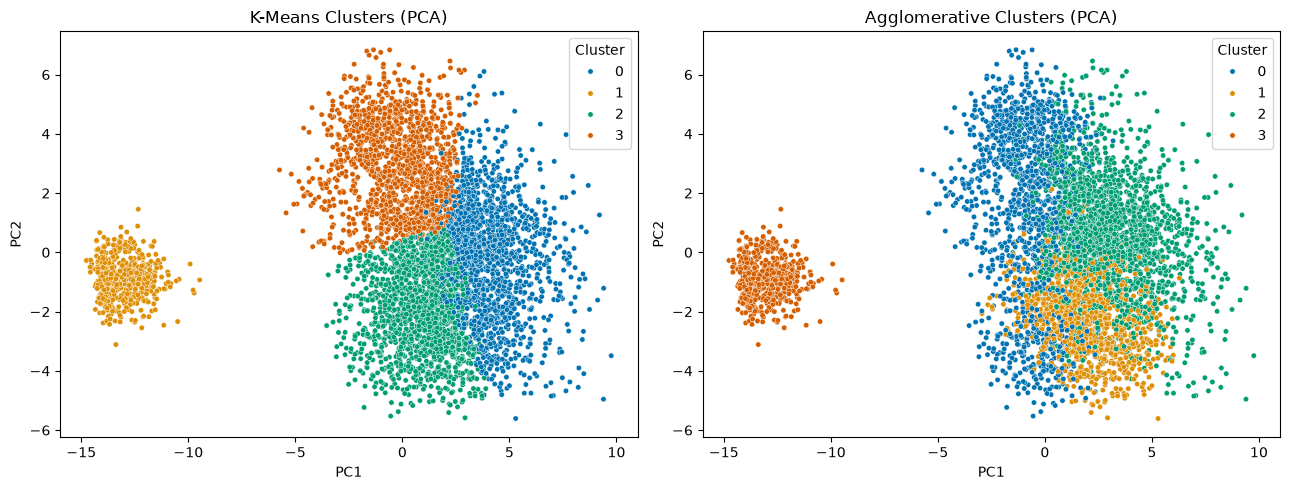

In [9]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
Xp = pca.fit_transform(Xs)
print('Variance explained:', pca.explained_variance_ratio_.round(3))

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for a, lab, name in [(ax[0], km_labels, 'K-Means'), (ax[1], agg_labels, 'Agglomerative')]:
    sns.scatterplot(x=Xp[:, 0], y=Xp[:, 1], hue=lab, palette='colorblind', s=15, ax=a)
    a.set(title=f'{name} Clusters (PCA)', xlabel='PC1', ylabel='PC2')
    a.legend(title='Cluster')
plt.tight_layout()
plt.savefig('../models/cluster_pca.png', bbox_inches='tight')
plt.show()

The first two principal components explain about 66% of the variance (PC1 53.9%, PC2 12.1%), so the 2D plots show about two-thirds of the structure and some separation may be hidden in the other dimensions. In both plots, one small group on the left is clearly separated from everything else, with a visible gap along PC1. The other three clusters sit close together in one connected cloud. K-Means splits that cloud into three fairly distinct regions (top, bottom and right) with relatively clean boundaries between them. Agglomerative also finds the separate group on the left, but its other three clusters overlap much more, especially the clusters in the middle and lower part of the cloud, so its boundaries are less clear. This agrees with the metrics above, where K-Means has the higher silhouette and Calinski-Harabasz scores and the lower Davies-Bouldin score. Overlap in a 2D projection does not necessarily mean the clusters overlap in the full feature space, so the plots support the metrics but do not replace them.

# 9. t-SNE (slow, so it uses 3,000 points)

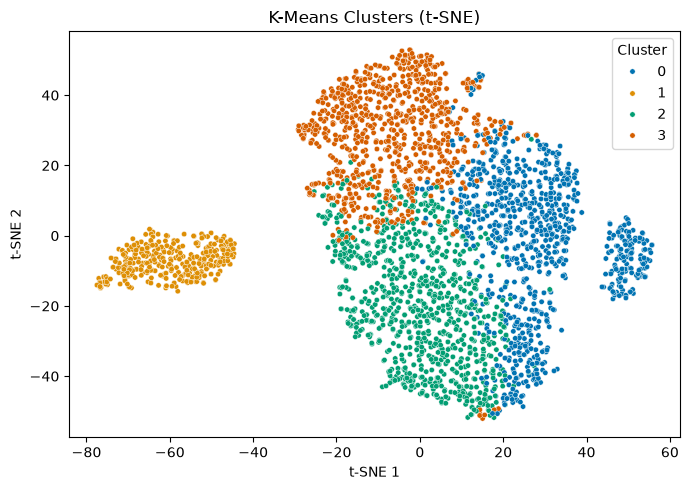

In [10]:
Xt = TSNE(n_components=2, perplexity=30, random_state=RANDOM_STATE).fit_transform(Xs[:3000])

plt.figure(figsize=(7, 5))
sns.scatterplot(x=Xt[:, 0], y=Xt[:, 1], hue=km_labels[:3000], palette='colorblind', s=15)
plt.title('K-Means Clusters (t-SNE)')
plt.xlabel('t-SNE 1')
plt.ylabel('t-SNE 2')
plt.legend(title='Cluster')
plt.tight_layout()
plt.savefig('../models/cluster_tsne.png', bbox_inches='tight')
plt.show()

t-SNE is run on the first 3,000 points of the sample (it is slow on larger data), with perplexity 30, and the points are coloured by the K-Means labels. Cluster 1 forms a tight, completely separate group on the left, as it does in the PCA plot. The other three clusters sit in one large connected region, with cluster 3 at the top, cluster 2 at the bottom and cluster 0 on the right. Their edges still mix, especially where clusters 3, 2 and 0 meet, so these clusters are not sharply separated. Cluster 0 also has a small group of points at the far right that is detached from the rest of the cluster, which PCA did not show clearly. This may mean cluster 0 contains a sub-group, but I have not investigated it. Compared with PCA, t-SNE separates the isolated group more clearly and shows local structure better, but it preserves local neighbourhoods and not global distances, so the sizes of the gaps and the positions of the groups should not be read as exact distances.

# 10. Validate against the true labels afterwards

In [11]:
print(pd.crosstab(km_labels, ys, rownames=['K-Means cluster'], colnames=['position_group']))
print()
print(pd.crosstab(agg_labels, ys, rownames=['Agglomerative cluster'], colnames=['position_group']))

position_group   Defender  Forward  Goalkeeper  Midfielder
K-Means cluster                                           
0                     354      347           0         832
1                       0        0         558           0
2                     176      592           0         770
3                    1145       11           0         215

position_group         Defender  Forward  Goalkeeper  Midfielder
Agglomerative cluster                                           
0                           932      117           0         349
1                             6      698           0         369
2                           737      135           0        1099
3                             0        0         558           0


The position labels are used only now, to interpret the clusters. They were never used when fitting.

**K-Means.** Cluster 1 holds all 558 goalkeepers in the sample and nobody else, so goalkeepers are separated perfectly. This is the isolated group in the PCA and t-SNE plots, and it explains the very high silhouette at k = 2 earlier. Cluster 3 is mostly defenders (1,145 of 1,371, about 84%). Cluster 2 is about half midfielders (770 of 1,538) and 38% forwards (592), so it leans attacking. Cluster 0 is the most mixed: 54% midfielders (832), with similar numbers of defenders (354) and forwards (347).

**Agglomerative (Ward).** Cluster 3 is again exactly the 558 goalkeepers. Cluster 0 leans defender (932 of 1,398, about 67%), cluster 1 leans forward (698 of 1,073, about 65%), and cluster 2 is a midfielder-heavy mix (1,099 of 1,971, about 56%, plus 737 defenders).

Both algorithms isolate the goalkeepers perfectly. This is partly a result of the cleaning step, where the outfield attributes (pace, shooting and so on) were set to 0 for goalkeepers and `goalkeeping_speed` was set to 0 for outfield players. That makes goalkeepers very different from everyone else in the feature space and so easy to separate. The outfield clusters lean towards a position but are not pure, which fits the overlap seen in the PCA and t-SNE plots and the low silhouette scores. As a rough check, if each cluster is named after its most common position, K-Means matches the true label for 3,305 of 5,000 players (66.1%) and Agglomerative for 3,287 (65.7%). By this measure the two are almost equal, even though K-Means is better on the internal metrics.

K-Means (k = 4) is the better algorithm on all three internal metrics (Silhouette 0.2278 vs 0.1805, Davies-Bouldin 1.4381 vs 1.7156, Calinski-Harabasz 2,703 vs 2,282). Both algorithms separate the goalkeepers cleanly, but the outfield positions overlap, so the clusters describe tendencies in player profiles and not sharp roles. Limitations: all results come from a 5,000-player sample, silhouette values are low, and the goalkeeper separation partly reflects how missing values were filled with 0 during cleaning.